# SFS income: household, per earner, per capita

Self-contained **Survey of Financial Security** notebook (no SHS).

For each of **market**, **net**, and **market + transfers** income, construct:

- household total
- per earner (`dem_num_earners`, 3+ → 3; requires ≥1 earner)
- per capita (`dem_fam_size`)

Report weighted **means** and **medians** for all households and for MIE ages **25–34**
(harmonized across 1999–2023). Plot time series by universe and by age band.

Requires `data/local_paths.yaml` (see `local_paths.example.yaml`).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.survey import (
    AGE_BANDS,
    DENOMS,
    INCOME_DEFS,
    INCOME_LABELS,
    INCOME_MEASURES,
    add_income_measures,
    income_moments,
    load_crea_avg_resale_price,
    load_crea_spreadsheet_price_income_ratios,
    load_local_paths,
    load_sfs,
    moments_wide,
    price_to_income_ratios,
)

paths = load_local_paths()
print("sfs_panel:", paths["sfs_panel"], "exists=", paths["sfs_panel"].exists())

out = ROOT / "output" / "survey"
out.mkdir(parents=True, exist_ok=True)
print("output ->", out)


sfs_panel: C:\Users\thoma\Dropbox\CA_costsinflation\data\raw\sfs\sfs1999_2023.csv exists= True
output -> c:\Users\thoma\Dropbox\HAmodel\portfolio_olg\output\survey


## Definitions

| Concept | Source |
|---------|--------|
| Market income | inc_gross / pefmtinc |
| Net (after-tax) | inc_net / pefatinc |
| Market + transfers | market + inc_transfers / pefgtr |
| Per earner | / dem_num_earners (0/1/2/3+; not stated dropped) |
| Per capita | / dem_fam_size (not stated dropped) |
| Age 25-34 | MIE age; continuous when available, else harmonized gegrp |

Age is the **major income earner**, not Census head. Family size is top-coded.

**Missing / residual codes:** StatCan dollar residuals such as 99999999 (not stated)
are set to NaN in load_sfs and excluded from weighted means/medians. In 2023 this
removes 790 market-income cases that would otherwise read as ~\ and inflate means.


In [2]:
sfs = add_income_measures(load_sfs())
print("N=", len(sfs), "years=", sorted(sfs["year"].dropna().unique().tolist()))
print("Age band counts:")
display(sfs["age_band"].value_counts().reindex(list(AGE_BANDS)))
display(
    sfs.groupby(["year", "age_band"], observed=False)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=list(AGE_BANDS))
)

N= 72295 years= [1999, 2005, 2012, 2016, 2019, 2023]
Age band counts:


age_band
<25       2518
25-34     9479
35-44    12522
45-54    13441
55-64    14031
65+      20304
Name: count, dtype: int64

age_band,<25,25-34,35-44,45-54,55-64,65+
year,,,,,,
1999,803,2699,3770,3139,2151,3371
2005,251,755,1092,1145,894,1130
2012,472,1506,1858,2494,2492,3181
2016,450,1673,1949,2314,2622,3421
2019,342,1412,1634,1853,2224,2957
2023,200,1434,2219,2496,3648,6244


## Weighted means and medians

In [3]:
mom_all = income_moments(sfs, by="year")
mom_all["universe"] = "all"
mom_2534 = income_moments(sfs, by="year", age_2534_only=True)
mom_2534["universe"] = "age_25_34"
mom_by_age = income_moments(sfs, by=["year", "age_band"])

wide_all = moments_wide(mom_all, index=("year",))
wide_2534 = moments_wide(mom_2534, index=("year",))

mom_all.to_csv(out / "sfs_income_moments_all.csv", index=False)
mom_2534.to_csv(out / "sfs_income_moments_age2534.csv", index=False)
mom_by_age.to_csv(out / "sfs_income_moments_by_age.csv", index=False)
wide_all.to_csv(out / "sfs_income_moments_all_wide.csv", index=False)
wide_2534.to_csv(out / "sfs_income_moments_age2534_wide.csv", index=False)

print("All households (wide mean/median):")
display(wide_all)
print("MIE ages 25–34:")
display(wide_2534)

All households (wide mean/median):


,year,inc_market_hh_mean,inc_market_hh_median,inc_market_per_capita_mean,inc_market_per_capita_median,inc_market_per_earner_mean,inc_market_per_earner_median,inc_market_transfer_hh_mean,inc_market_transfer_hh_median,inc_market_transfer_per_capita_mean,inc_market_transfer_per_capita_median,inc_market_transfer_per_earner_mean,inc_market_transfer_per_earner_median,inc_net_hh_mean,inc_net_hh_median,inc_net_per_capita_mean,inc_net_per_capita_median,inc_net_per_earner_mean,inc_net_per_earner_median
0,1999,43074.456691,33175.0,19215.326916,14716.666667,31676.200007,27500.000000,49174.518420,39500.0,22509.079423,17725.0,34630.044912,30000.000000,39495.317345,33400.0,18141.644951,15150.000000,27549.501274,24833.333333
1,2005,52466.012576,37000.0,23774.810707,18750.000000,38130.674474,32000.000000,59406.417074,45000.0,27553.980393,22175.0,41820.365482,35083.333333,49032.220735,39325.0,22790.554973,19475.000000,34236.197371,30000.000000
2,2012,65853.446159,48000.0,29548.594692,22500.000000,47234.741058,38333.333333,74791.785575,57500.0,34338.033186,27125.0,52131.485881,43366.666667,62797.159850,50500.0,29030.876139,24100.000000,43555.283267,37662.500000
3,2016,73760.223239,52500.0,33862.764406,25000.000000,53928.282328,43000.000000,83757.635464,63000.0,39279.254974,30975.0,59682.294294,48750.000000,69338.414751,55750.0,32705.823196,27262.500000,49123.124725,42075.000000
4,2019,78046.226031,57500.0,36726.409369,29000.000000,57190.708846,46250.000000,89441.298132,68000.0,43018.346618,35000.0,63659.138878,52766.666667,74080.987351,59500.0,35850.047978,30733.333333,52335.143674,45575.000000
5,2023,90606.397204,67500.0,43681.129096,35000.000000,67970.058408,55000.000000,104597.529821,80000.0,51584.055582,42250.0,75663.400197,63250.000000,86195.374992,70375.0,42665.206964,37200.000000,61856.122914,54262.500000


MIE ages 25–34:


,year,inc_market_hh_mean,inc_market_hh_median,inc_market_per_capita_mean,inc_market_per_capita_median,inc_market_per_earner_mean,inc_market_per_earner_median,inc_market_transfer_hh_mean,inc_market_transfer_hh_median,inc_market_transfer_per_capita_mean,inc_market_transfer_per_capita_median,inc_market_transfer_per_earner_mean,inc_market_transfer_per_earner_median,inc_net_hh_mean,inc_net_hh_median,inc_net_per_capita_mean,inc_net_per_capita_median,inc_net_per_earner_mean,inc_net_per_earner_median
0,1999,40999.239912,36000.0,20286.995241,16250.0,28606.338268,26225.0,44922.304926,39050.0,21794.799284,17693.75,30981.119486,28550.000000,36660.255280,32950.0,17667.949707,14800.00,25207.172809,23800.000000
1,2005,47483.019493,38000.0,25071.865609,22000.0,32964.130776,31250.0,51469.331674,42000.0,26608.844933,22675.00,35681.105303,33225.000000,43414.958613,36550.0,22320.120637,20025.00,30101.067352,28466.666667
2,2012,58969.634986,52500.0,29219.817406,25000.0,39218.562641,34000.0,64895.206569,57500.0,31434.646475,27475.00,42634.378583,37833.333333,55688.788854,50000.0,26924.322274,23931.25,36596.812000,33800.000000
3,2016,65538.885742,57500.0,33492.808916,27000.0,44351.668317,38750.0,71546.053699,63200.0,35743.628821,29500.00,48257.009286,42500.000000,60997.355294,55450.0,30309.323659,26275.00,41030.695939,37625.000000
4,2019,72810.361417,62500.0,37521.537455,32500.0,46537.376488,42500.0,79840.142268,70000.0,40179.683746,35487.50,50788.096153,47050.000000,68351.195015,61100.0,34209.425852,31550.00,43396.599890,41375.000000
5,2023,91523.190991,80000.0,48468.164482,45000.0,60094.638668,55000.0,100076.094622,88175.0,51631.640460,47750.00,65084.024906,59000.000000,84849.976546,77125.0,43306.588249,41200.00,54729.704345,50650.000000


## Figure 1 — All households vs MIE 25–34

Rows = income definition (market / net / market+transfers).  
Columns = universe. Within each panel: per-household, per-earner, per-capita;  
**solid = mean**, **dashed = median**.

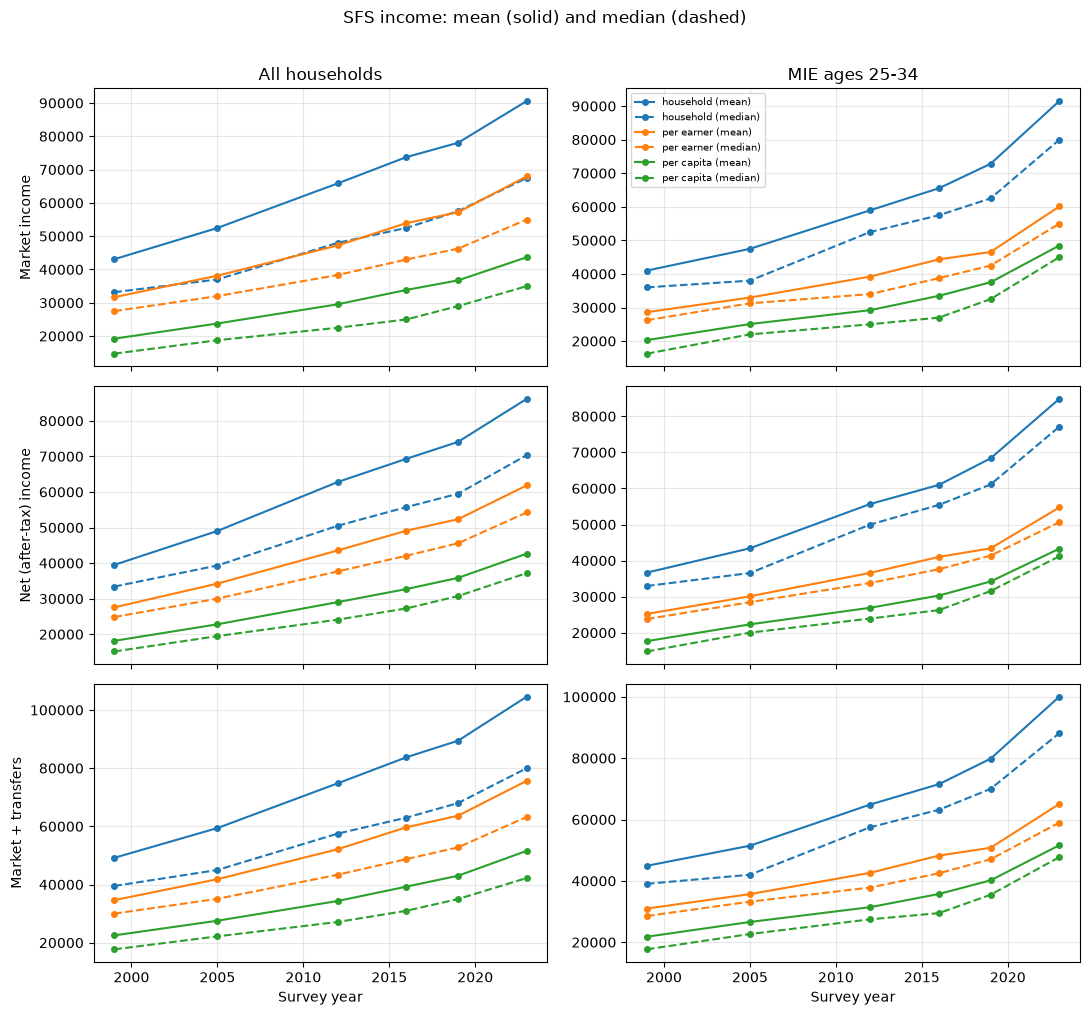

In [4]:
denom_styles = {
    "hh": {"color": "C0", "label": "household"},
    "per_earner": {"color": "C1", "label": "per earner"},
    "per_capita": {"color": "C2", "label": "per capita"},
}
def_titles = {
    "market": "Market income",
    "net": "Net (after-tax) income",
    "market_transfer": "Market + transfers",
}

combo = pd.concat([mom_all, mom_2534], ignore_index=True)
universes = [("all", "All households"), ("age_25_34", "MIE ages 25-34")]

fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
for r, d in enumerate(INCOME_DEFS):
    for c_i, (uni_key, uni_title) in enumerate(universes):
        ax = axes[r, c_i]
        sub = combo[combo["universe"] == uni_key]
        for k, sty in denom_styles.items():
            var = f"inc_{d}_{k}"
            for stat, ls in (("mean", "-"), ("median", "--")):
                ser = sub[(sub["variable"] == var) & (sub["stat"] == stat)].sort_values("year")
                ax.plot(
                    ser["year"],
                    ser["value"],
                    ls=ls,
                    color=sty["color"],
                    marker="o",
                    ms=4,
                    label=f"{sty['label']} ({stat})",
                )
        if r == 0:
            ax.set_title(uni_title)
        if c_i == 0:
            ax.set_ylabel(def_titles[d])
        ax.grid(True, alpha=0.3)
        if r == 0 and c_i == 1:
            ax.legend(fontsize=7, loc="best")

axes[-1, 0].set_xlabel("Survey year")
axes[-1, 1].set_xlabel("Survey year")
fig.suptitle("SFS income: mean (solid) and median (dashed)", y=1.01)
fig.tight_layout()
fig.savefig(out / "sfs_income_fig1_universe.png", dpi=140, bbox_inches="tight")
plt.show()


## Figure 1b — Means only (all households vs MIE 25–34)

Same layout as Figure 1, but **weighted means only** (no medians).


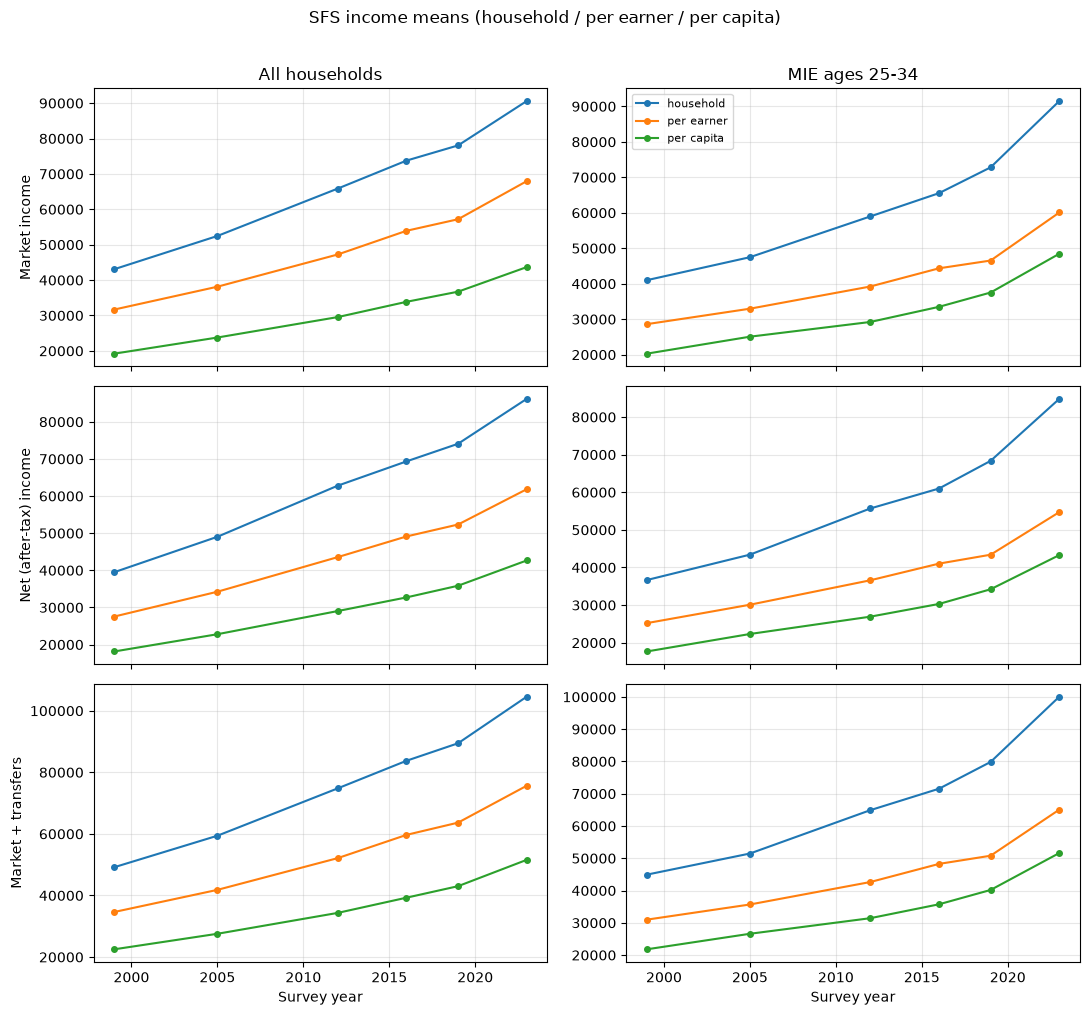

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
for r, d in enumerate(INCOME_DEFS):
    for c_i, (uni_key, uni_title) in enumerate(universes):
        ax = axes[r, c_i]
        sub = combo[combo["universe"] == uni_key]
        for k, sty in denom_styles.items():
            var = f"inc_{d}_{k}"
            ser = sub[(sub["variable"] == var) & (sub["stat"] == "mean")].sort_values("year")
            ax.plot(
                ser["year"],
                ser["value"],
                color=sty["color"],
                marker="o",
                ms=4,
                label=sty["label"],
            )
        if r == 0:
            ax.set_title(uni_title)
        if c_i == 0:
            ax.set_ylabel(def_titles[d])
        ax.grid(True, alpha=0.3)
        if r == 0 and c_i == 1:
            ax.legend(fontsize=8, loc="best")

axes[-1, 0].set_xlabel("Survey year")
axes[-1, 1].set_xlabel("Survey year")
fig.suptitle("SFS income means (household / per earner / per capita)", y=1.01)
fig.tight_layout()
fig.savefig(out / "sfs_income_fig1b_means_only.png", dpi=140, bbox_inches="tight")
plt.show()


## CREA house price / mean income

CREA Canada **average residential sale price** (`data/HousePriceIndices.xlsx`,
sheet *Average Resale Price, CREA*) divided by each SFS weighted **mean** income
measure, for all households and MIE ages 25–34.

Same multipanel layout as Figure 1b. **Bold dashed** lines overlay the spreadsheet’s
own CREA price / StatCan average income ratios for ages **25–34** and **35–44**
(excluding zero incomes) on every panel.


In [ ]:
crea_xlsx = ROOT / "data" / "HousePriceIndices.xlsx"
crea = load_crea_avg_resale_price(crea_xlsx)
crea_sheet = load_crea_spreadsheet_price_income_ratios(crea_xlsx, including_zeros=False)
sfs_years = sorted(int(y) for y in sfs["year"].dropna().unique())
display(crea.reindex(sfs_years).to_frame("crea_avg_price"))
display(crea_sheet[["25 to 34 years", "35 to 44 years"]].reindex(sfs_years).dropna(how="all"))

pty = price_to_income_ratios(combo, crea)
pty.to_csv(out / "sfs_crea_price_to_income.csv", index=False)
display(pty.head(18))

# Spreadsheet age ratios (CREA / StatCan avg income, excl. zeros): bold dashed overlays
sheet_line_styles = {
    "25 to 34 years": {"color": "#333333", "label": "xls 25–34 excl.0"},
    "35 to 44 years": {"color": "#777777", "label": "xls 35–44 excl.0"},
}

fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
for r, d in enumerate(INCOME_DEFS):
    for c_i, (uni_key, uni_title) in enumerate(universes):
        ax = axes[r, c_i]
        sub = pty[pty["universe"] == uni_key]
        for k, sty in denom_styles.items():
            var = f"inc_{d}_{k}"
            ser = sub[sub["variable"] == var].sort_values("year")
            ax.plot(
                ser["year"],
                ser["price_to_income"],
                color=sty["color"],
                marker="o",
                ms=4,
                label=sty["label"],
            )
        for col, sty in sheet_line_styles.items():
            if col not in crea_sheet.columns:
                continue
            ser = crea_sheet[col].dropna()
            ax.plot(
                ser.index,
                ser.values,
                color=sty["color"],
                ls="--",
                lw=2.4,
                label=sty["label"],
            )
        if r == 0:
            ax.set_title(uni_title)
        if c_i == 0:
            ax.set_ylabel(f"CREA price / mean {def_titles[d].lower()}")
        ax.grid(True, alpha=0.3)
        if r == 0 and c_i == 1:
            ax.legend(fontsize=7, loc="best")

axes[-1, 0].set_xlabel("Survey year")
axes[-1, 1].set_xlabel("Survey year")
fig.suptitle(
    "CREA average house price / SFS mean income\n"
    "(bold dashed: spreadsheet CREA/StatCan ratios, ages 25–34 & 35–44, excl. zeros)",
    y=1.02,
)
fig.tight_layout()
fig.savefig(out / "sfs_crea_price_to_income.png", dpi=140, bbox_inches="tight")
plt.show()


## Figure 2 — Income measures by MIE age band

One panel per income series (definition × denominator).  
Lines = harmonized age bands; **weighted means** only.

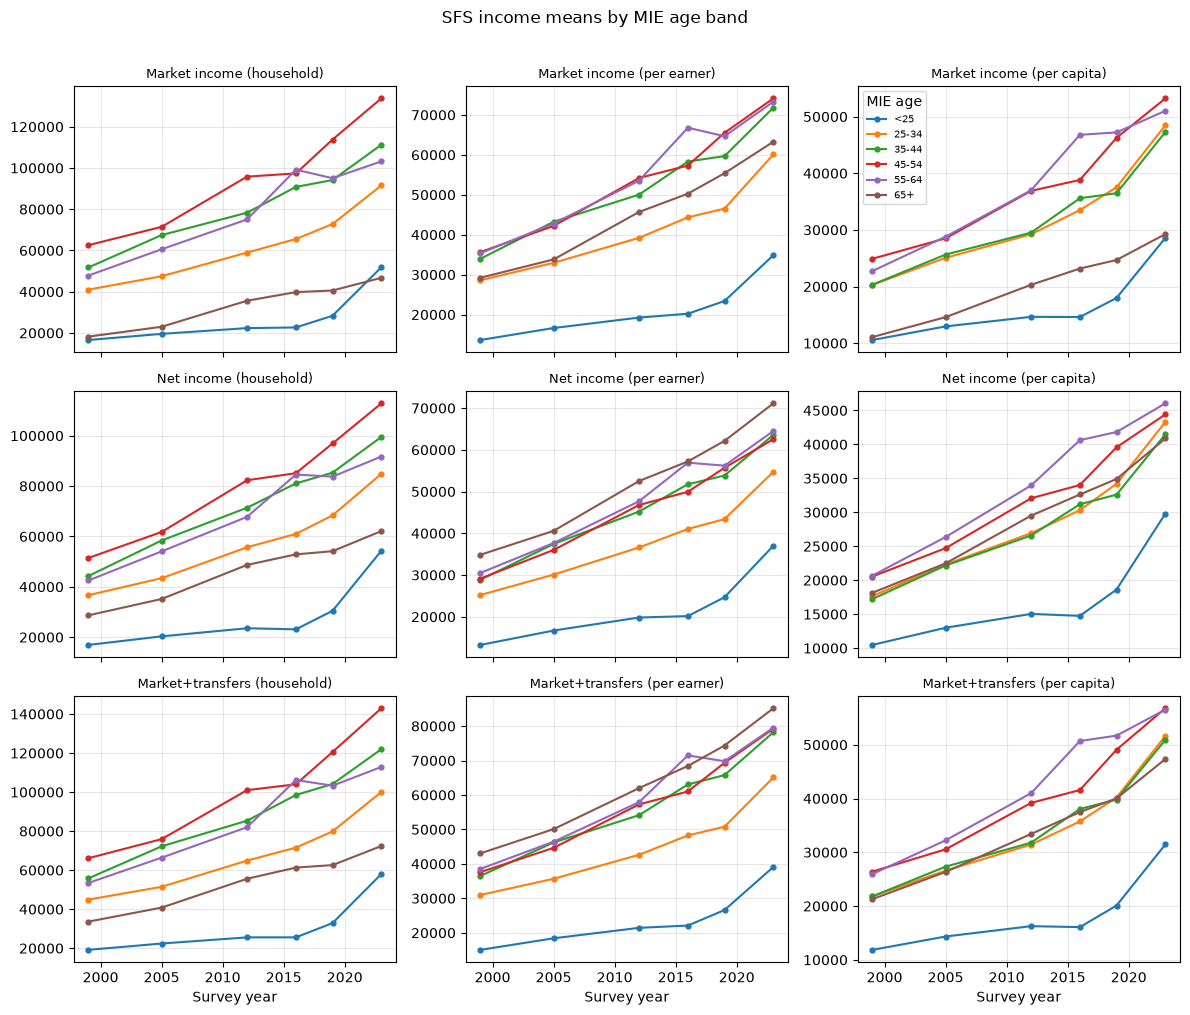

In [8]:
means = mom_by_age[mom_by_age["stat"] == "mean"].copy()
means = means[means["age_band"].isin(AGE_BANDS)]

fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True)
for i, d in enumerate(INCOME_DEFS):
    for j, k in enumerate(DENOMS):
        ax = axes[i, j]
        var = f"inc_{d}_{k}"
        for band in AGE_BANDS:
            ser = means[(means["variable"] == var) & (means["age_band"] == band)].sort_values("year")
            ax.plot(ser["year"], ser["value"], marker="o", ms=3.5, label=band)
        ax.set_title(INCOME_LABELS.get(var, var), fontsize=9)
        ax.grid(True, alpha=0.3)
        if i == 0 and j == 2:
            ax.legend(fontsize=7, title="MIE age", loc="best")

for ax in axes[-1, :]:
    ax.set_xlabel("Survey year")
fig.suptitle("SFS income means by MIE age band", y=1.01)
fig.tight_layout()
fig.savefig(out / "sfs_income_fig2_by_age.png", dpi=140, bbox_inches="tight")
plt.show()

## Notes

- Loader inc_gross is **market** income, not total pre-tax; market_transfer adds government transfers.
- Residual codes (99999996–99999999, and 9-digit analogues) are scrubbed to NaN — not zero.
- Earners are a count (0/1/2/3+), not hours-based employment.
- Per-capita uses top-coded family size where applicable.
- Housing price / wealth / income ratios are out of scope here (income side only).
